# IMPORT

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import folium
import csv
import json
import os

# DEFINE FOLDERS

In [2]:
BASE_FOLDER = Path("../data")
JSON_INPUT_FOLDER = BASE_FOLDER / "00_raw" / "json" / "correlated_data_json"
DATASET_INPUT_FOLDER = BASE_FOLDER / "00_raw" / "csv" / "correlated_data_csv"
DATASET_OUTPUT_FOLDER = BASE_FOLDER / "01_clean" / "datasets"
DELETED_STATIONS_FOLDER = BASE_FOLDER / "01_clean" / "deleted_stations"
MAP_FOLDER = BASE_FOLDER / "05_visualization" / "maps"
COORDINATES_FOLDER = BASE_FOLDER / "02_features" / "station_coordinates"
PIPELINE_STATS_FOLDER = BASE_FOLDER / "06_statistics" / "pipeline"

folders = [JSON_INPUT_FOLDER, DATASET_INPUT_FOLDER, DATASET_OUTPUT_FOLDER, DELETED_STATIONS_FOLDER, MAP_FOLDER, COORDINATES_FOLDER, PIPELINE_STATS_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE CONSTANTS

In [ ]:
REMAKE_CSV = False # To get the dataset from json files(will be saved in a csv file)
CSV_FILE_NAME = "correlated_data" #To save the dataset from json to csv/to get the dataset from csv
FINAL_CSV_FILE_NAME = "final_clean_split_data" # The prepared dataset

# DEFINE VARIABLES

In [4]:
# Not exactly variables as we will modify them only once at the start
TOTAL_ROWS_AT_START = 1 # 1 to avoid division by zero
TOTAL_REAL_ROWS_AT_START = 1
TOTAL_STATIONS_AT_START = 1
TOTAL_REAL_STATIONS_AT_START = 1
pipeline_stats = [] 

# DEFINE FUNCS

In [5]:
def log_pipeline_step(df, step_name):
    station_col = "station_code" if "station_code" in df.columns else "stationcode" 
    pipeline_stats.append({ 
        "step": step_name, 
        "rows": df.shape[0], 
        "stations": df[station_col].nunique() 
        })

def print_df(dataframe):
    print("=========================================")
    print(f"Dataframe analysis")
    print("-----------------------")
    print(f"Shape: \nrows:     {dataframe.shape[0]}\nfeatures: {dataframe.shape[1]}")
    
    # Size of the dataframe it takes in RAM
    data_size_bytes = dataframe.memory_usage(deep=True).sum()
    data_size_mb = data_size_bytes / (1024**2)
    print(f"Dataframe size: {data_size_bytes} bytes ({data_size_mb:.2f} MB)")

    print("-----------------------")

    # We do this because at one point we change the column's name
    station_col = "station_code" if "station_code" in dataframe.columns else "stationcode"

    rows_pct = (TOTAL_ROWS_AT_START - dataframe.shape[0]) / TOTAL_ROWS_AT_START * 100
    stations_pct = (TOTAL_STATIONS_AT_START - dataframe[station_col].nunique()) / TOTAL_STATIONS_AT_START * 100
    real_rows_pct = (TOTAL_REAL_ROWS_AT_START - dataframe.shape[0]) / TOTAL_REAL_ROWS_AT_START * 100
    real_stations_pct = (TOTAL_REAL_STATIONS_AT_START - dataframe[station_col].nunique()) / TOTAL_REAL_STATIONS_AT_START * 100

    print(f"Percentage of rows removed: {rows_pct:.2f}%")
    print(f"Percentage of stations removed: {stations_pct:.2f}%")
    print(f"Percentage of real rows removed: {real_rows_pct:.2f}%")
    print(f"Percentage of real stations removed: {real_stations_pct:.2f}%")

    print("-----------------------")
    # To see what columns we have as what data type
    display(dataframe.dtypes)
    print("-----------------------")
    # Basic statistics
    display(dataframe.describe())
    print("=========================================")

MISSING_STRINGS = {"", "na", "n/a", "null", "none", "nan", "-"}
def rows_with_missing(df):
    # NaN anywhere
    mask = df.isna().any(axis=1)

    # Only object columns
    obj_df = df.select_dtypes(include="object")

    if not obj_df.empty:
        # Normalize all strings
        normalized = obj_df.apply(
            lambda col: col.str.strip().str.lower()
        )

        # Check missing-like strings (row-wise)
        string_missing = normalized.isin(MISSING_STRINGS).any(axis=1)

        # Add missing strings to mask
        mask |= string_missing

    return df[mask]

def print_missing(dataframe, max_rows=10):
    print("=========================================")
    print(f"Missing diagnostics")
    print("-----------------------")

    # NaN count per column
    nan_counts = dataframe.isna().sum().sort_values(ascending=False)

    # Inf count per numeric column
    numeric_df = dataframe.select_dtypes(include=[np.number])
    inf_counts = np.isinf(numeric_df).sum()

    problem_counts = (
        pd.DataFrame({
            "nan": nan_counts,
            "inf": inf_counts
        })
        .fillna(0)
        .astype(int)
        .sort_values(by=["nan", "inf"], ascending=False)
    )

    print("\nNaN / Inf per column:")
    display(problem_counts)

    print("-----------------------")

    # missing_rows = rows_with_missing(dataframe)
    # print(f"\nRows with missing-like values: {len(missing_rows)}")
    # display(missing_rows.head(max_rows))

    print("=========================================")



# IF WANT TO REMAKE CSV FILE FROM JSON FILES

In [6]:
CHUNK_SIZE = 50_000   # chunk size to save each time to CSV_FILE_NAME, so the memory doesn't explode
first_write = True

csv_path = os.path.join(DATASET_INPUT_FOLDER, f"{CSV_FILE_NAME}.csv")
total_file_num = len(os.listdir(JSON_INPUT_FOLDER))

if REMAKE_CSV:
    for file_idx, filename in enumerate(os.listdir(JSON_INPUT_FOLDER), start=1):
        if not filename.endswith(".json"):
            continue

        path = os.path.join(JSON_INPUT_FOLDER, filename)

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        rows = []

        for entry in data:
            row = {}

            # Station fields
            fields = entry.get("fields", {})
            for key, value in fields.items():
                if key == "coordonnees_geo" and isinstance(value, list) and len(value) == 2:
                    row["latitude"] = value[0]
                    row["longitude"] = value[1]
                else:
                    row[key] = value

            # Weather fields
            weather = entry.get("weather", {})
            if "time" in weather:
                row["weather_time"] = weather["time"]

            for key, value in weather.items():
                if key != "time":
                    row[f"weather_{key}"] = value

            row["source_file"] = filename
            rows.append(row)

            # Write chunk
            if len(rows) >= CHUNK_SIZE:
                df_chunk = pd.DataFrame(rows)
                df_chunk.to_csv(
                    csv_path,
                    mode="w" if first_write else "a",
                    header=first_write,
                    index=False,
                    encoding="utf-8"
                )
                first_write = False
                rows.clear()

        # Flush remaining rows of this file
        if rows:
            df_chunk = pd.DataFrame(rows)
            df_chunk.to_csv(
                csv_path,
                mode = "w" if first_write else "a",
                header = first_write,
                index = False,
                encoding="utf-8"
            )
            first_write = False

        if file_idx % 100 == 0:
            print(f"{file_idx}/{total_file_num} JSON files processed")

    print("CSV generation finished.")

100/8406 JSON files processed
200/8406 JSON files processed
300/8406 JSON files processed
400/8406 JSON files processed
500/8406 JSON files processed
600/8406 JSON files processed
700/8406 JSON files processed
800/8406 JSON files processed
900/8406 JSON files processed
1000/8406 JSON files processed
1100/8406 JSON files processed
1200/8406 JSON files processed
1300/8406 JSON files processed
1400/8406 JSON files processed
1500/8406 JSON files processed
1600/8406 JSON files processed
1700/8406 JSON files processed
1800/8406 JSON files processed
1900/8406 JSON files processed
2000/8406 JSON files processed
2100/8406 JSON files processed
2200/8406 JSON files processed
2300/8406 JSON files processed
2400/8406 JSON files processed
2500/8406 JSON files processed
2600/8406 JSON files processed
2700/8406 JSON files processed
2800/8406 JSON files processed
2900/8406 JSON files processed
3000/8406 JSON files processed
3100/8406 JSON files processed
3200/8406 JSON files processed
3300/8406 JSON fi

# LOAD DATA

In [7]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")
log_pipeline_step(df, "Initial dataframe")
df.head(5)

C:\Users\emirh\AppData\Local\Temp\ipykernel_54500\2113075812.py:1: DtypeWarning: Columns (2,3,4,5,8,9,14,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")


,name,stationcode,ebike,mechanical,latitude,longitude,duedate,numbikesavailable,numdocksavailable,capacity,...,is_returning,code_insee_commune,weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
0,Cassini - Denfert-Rochereau,14111,2,0,48.837526,2.336035,2025-11-04T03:25:04+00:00,2.0,22,25,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
1,Basilique,32017,5,1,48.936269,2.358867,2025-11-04T03:21:03+00:00,6.0,16,22,...,OUI,93066,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
2,Charonne - Robert et Sonia Delaunay,11104,1,1,48.855908,2.392571,2025-11-04T03:29:35+00:00,2.0,18,20,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
3,Lacépède - Monge,5110,1,6,48.843893,2.351966,2025-11-04T03:30:23+00:00,7.0,15,23,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
4,Saint-Romain - Cherche-Midi,6108,2,2,48.847082,2.321375,2025-11-04T03:28:05+00:00,4.0,11,17,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json


In [8]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     12607312
features: 23
Dataframe size: 11684797746 bytes (11143.49 MB)
-----------------------
Percentage of rows removed: -1260731100.00%
Percentage of stations removed: -159400.00%
Percentage of real rows removed: -1260731100.00%
Percentage of real stations removed: -159400.00%
-----------------------


name                            object
stationcode                      int64
ebike                           object
mechanical                      object
latitude                        object
longitude                       object
duedate                         object
numbikesavailable              float64
numdocksavailable               object
capacity                        object
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune              object
weather_time                    object
weather_interval                object
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,numbikesavailable,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,1.260731e+07,1.253085e+07,1.239662e+07,1.239662e+07,1.239662e+07,1.239662e+07,1.239662e+07
mean,1.888899e+04,1.261573e+01,1.015534e+01,3.924098e-01,1.002260e+01,1.814410e+02,1.599036e+01
std,1.246029e+04,1.111013e+01,4.902938e+01,6.635110e-01,4.824002e+00,7.390184e+01,2.691925e+01
min,0.000000e+00,0.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102600e+04,4.000000e+00,4.800000e+00,0.000000e+00,6.600000e+00,1.450000e+02,3.000000e+00
50%,1.700300e+04,1.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230500e+04,1.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,8.400000e+01,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.600000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
weather_interval,210695,0
weather_is_day,210695,0
weather_temperature_2m,210695,0
weather_weather_code,210695,0
weather_wind_direction_10m,210695,0
weather_wind_speed_10m,210695,0
weather_time,207041,0
code_insee_commune,146772,0
nom_arrondissement_communes,146772,0
source_file,144215,0


-----------------------


# SET VARIABLES

In [9]:
TOTAL_ROWS_AT_START = df.shape[0]
TOTAL_STATIONS_AT_START = df["stationcode"].nunique()
TOTAL_REAL_ROWS_AT_START = df.shape[0] # We will change this after removing the obsolete stations
TOTAL_REAL_STATIONS_AT_START = df["stationcode"].nunique() # We will change this after removing the obsolete stations
print(f"{TOTAL_ROWS_AT_START=}")
print(f"{TOTAL_STATIONS_AT_START=}")
print(f"{TOTAL_REAL_ROWS_AT_START=}")
print(f"{TOTAL_REAL_STATIONS_AT_START=}")

TOTAL_ROWS_AT_START=12607312
TOTAL_STATIONS_AT_START=1595
TOTAL_REAL_ROWS_AT_START=12607312
TOTAL_REAL_STATIONS_AT_START=1595


# FORCE NUMERIC VALUES TO BE NUMERIC

In [10]:
MISSING_STRINGS = {"", "na", "n/a", "null", "none", "nan", "-"}

# Normalize missing-like strings
df = df.replace(list(MISSING_STRINGS), np.nan)

# Columns that must be numeric
NUMERIC_COLS = [
    "latitude",
    "longitude",
    "capacity",
    "numbikesavailable",
    "numdocksavailable",
    "weather_temperature_2m",
    "weather_is_day",
    "weather_wind_speed_10m",
    "weather_wind_direction_10m",
    "weather_weather_code",
]

for col in NUMERIC_COLS:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce") # coerce to set to nan

df.replace([np.inf, -np.inf], np.nan, inplace=True)


In [11]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     12607312
features: 23
Dataframe size: 10220803080 bytes (9747.32 MB)
-----------------------
Percentage of rows removed: 0.00%
Percentage of stations removed: 0.00%
Percentage of real rows removed: 0.00%
Percentage of real stations removed: 0.00%
-----------------------


name                            object
stationcode                      int64
ebike                           object
mechanical                      object
latitude                       float64
longitude                      float64
duedate                         object
numbikesavailable              float64
numdocksavailable              float64
capacity                       float64
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune              object
weather_time                    object
weather_interval                object
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,latitude,longitude,numbikesavailable,numdocksavailable,capacity,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,1.260731e+07,1.245264e+07,1.252464e+07,1.253085e+07,1.245885e+07,1.245264e+07,1.239662e+07,1.239662e+07,1.239662e+07,1.239662e+07,1.239662e+07
mean,1.888899e+04,4.885778e+01,2.355107e+00,1.261573e+01,1.826999e+01,3.187419e+01,1.015534e+01,3.924098e-01,1.002260e+01,1.814410e+02,1.599036e+01
std,1.246029e+04,3.269908e-02,3.614848e-01,1.111013e+01,1.227087e+01,1.258745e+01,4.902938e+01,6.635110e-01,4.824002e+00,7.390184e+01,2.691925e+01
min,0.000000e+00,4.874339e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102600e+04,4.883672e+01,2.302569e+00,4.000000e+00,9.000000e+00,2.300000e+01,4.800000e+00,0.000000e+00,6.600000e+00,1.450000e+02,3.000000e+00
50%,1.700300e+04,4.885826e+01,2.344139e+00,1.000000e+01,1.700000e+01,3.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230500e+04,4.887951e+01,2.381134e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,4.800000e+01,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.600000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
weather_interval,210695,0
weather_is_day,210695,0
weather_temperature_2m,210695,0
weather_weather_code,210695,0
weather_wind_direction_10m,210695,0
weather_wind_speed_10m,210695,0
weather_time,207041,0
capacity,154672,0
latitude,154672,0
numdocksavailable,148461,0


-----------------------


# RENAME FEATURES(COLUMNS)

In [12]:
feature_name_dict = {
    "name": "station_name",
    "stationcode": "station_code",
    "numbikesavailable": "total_bikes_now",
    "numdocksavailable": "total_bikes_taken",
    "nom_arrondissement_communes": "commune_name",
    "code_insee_commune": "postal_code",
    "weather_time": "timestamp",
    "weather_temperature_2m": "temperature",
    "weather_is_day": "is_day",
    "weather_wind_speed_10m": "wind_speed",
    "weather_wind_direction_10m": "wind_direction",
    "weather_weather_code": "weather_code"
}

df = df.rename(columns=feature_name_dict)

# CHECK

In [13]:
print_missing(df)

Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,210695,0
temperature,210695,0
weather_code,210695,0
weather_interval,210695,0
wind_direction,210695,0
wind_speed,210695,0
timestamp,207041,0
capacity,154672,0
latitude,154672,0
total_bikes_taken,148461,0


-----------------------


# DETECT ANOMALIES

Total stations: 1595
Sum of num_stations: 1510
Stations with no valid capacity:  85


,capacity,num_stations
0,0.0,2
1,1.0,3
2,10.0,1
3,11.0,3
4,12.0,5
...,...,...
63,74.0,3
64,75.0,1
65,76.0,1
66,78.0,3


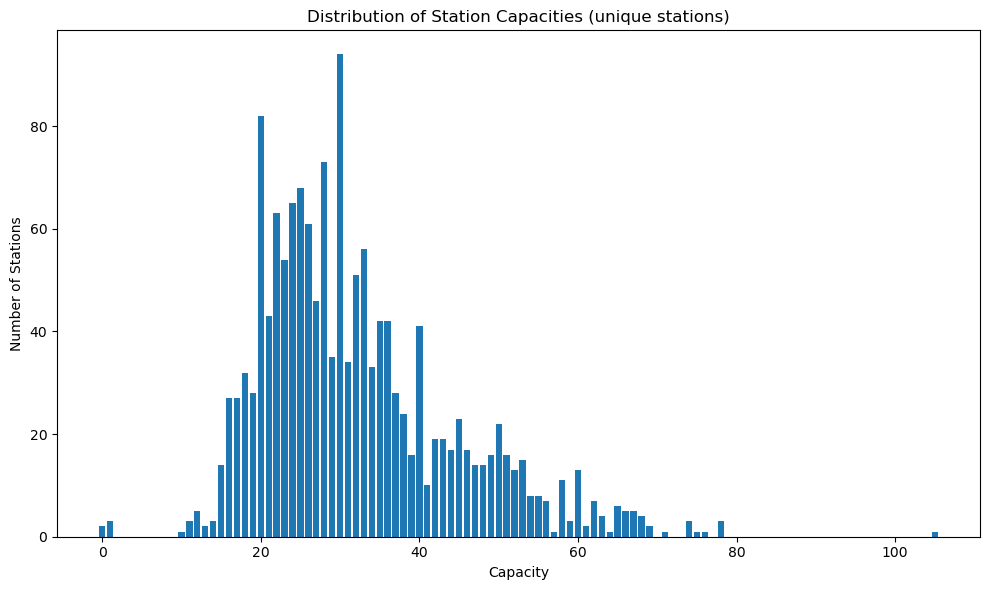

In [14]:
# Only one row per station_code to get unique capacities
station_capacity = (
    df.groupby("station_code")["capacity"]
      .max()
      .reset_index()
)

# Count how many stations have each capacity
capacity_counts = (
    station_capacity["capacity"]
    .value_counts()
    .sort_index()
    .reset_index()
)

capacity_counts.columns = ["capacity", "num_stations"]

print(f"Total stations: {station_capacity.shape[0]}")
print(f"Sum of num_stations:", capacity_counts["num_stations"].sum())
print(f"Stations with no valid capacity: ", (station_capacity.shape[0] - capacity_counts["num_stations"].sum()))


display(capacity_counts)


# Plot
plt.figure(figsize=(10,6))
plt.bar(capacity_counts["capacity"], capacity_counts["num_stations"])
plt.xlabel("Capacity")
plt.ylabel("Number of Stations")
plt.title("Distribution of Station Capacities (unique stations)")
plt.tight_layout()
plt.show()


# REMOVE THE ONES WITH VERY LOW CAPACITY NUMBER

In [15]:
bad_capacity_stations = station_capacity[
    station_capacity["capacity"] <= 1 # We choose 1 by looking at the histogram 
]["station_code"]

print("Stations to remove:", len(bad_capacity_stations))

Stations to remove: 5


In [16]:
df.describe()

,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,1.260731e+07,1.245264e+07,1.252464e+07,1.253085e+07,1.245885e+07,1.245264e+07,1.239662e+07,1.239662e+07,1.239662e+07,1.239662e+07,1.239662e+07
mean,1.888899e+04,4.885778e+01,2.355107e+00,1.261573e+01,1.826999e+01,3.187419e+01,1.015534e+01,3.924098e-01,1.002260e+01,1.814410e+02,1.599036e+01
std,1.246029e+04,3.269908e-02,3.614848e-01,1.111013e+01,1.227087e+01,1.258745e+01,4.902938e+01,6.635110e-01,4.824002e+00,7.390184e+01,2.691925e+01
min,0.000000e+00,4.874339e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102600e+04,4.883672e+01,2.302569e+00,4.000000e+00,9.000000e+00,2.300000e+01,4.800000e+00,0.000000e+00,6.600000e+00,1.450000e+02,3.000000e+00
50%,1.700300e+04,4.885826e+01,2.344139e+00,1.000000e+01,1.700000e+01,3.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230500e+04,4.887951e+01,2.381134e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,4.800000e+01,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.600000e+02


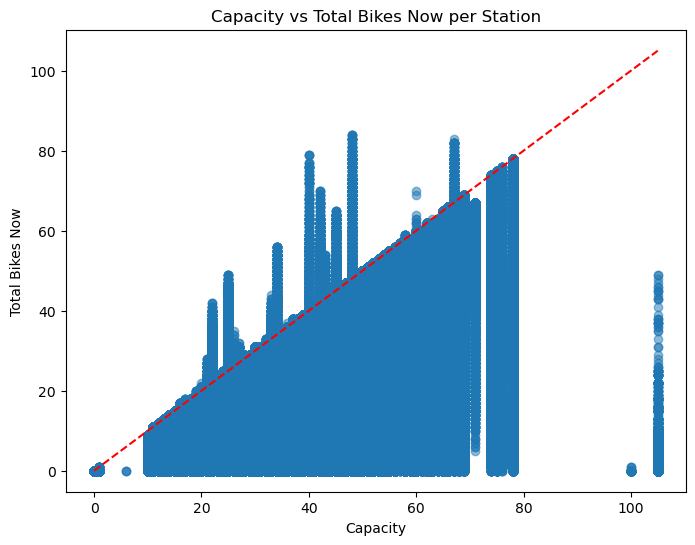

In [17]:
plt.figure(figsize=(8,6))
plt.scatter(df["capacity"], df["total_bikes_now"], alpha=0.5)
plt.plot([0, df["capacity"].max()], [0, df["capacity"].max()], color="red", linestyle="--")
plt.xlabel("Capacity")
plt.ylabel("Total Bikes Now")
plt.title("Capacity vs Total Bikes Now per Station")
plt.show()

# REMOVE BAD CAPACITY STATIONS

In [18]:
# ~ means not in pandas
df = df[~df["station_code"].isin(bad_capacity_stations)] # Removing whole stations
log_pipeline_step(df, "Drop Stations with Capacity < 2")
print_df(df)
df = df[df["capacity"] > 1] # Removing rows
log_pipeline_step(df, "Drop Rows with Capacity < 2")
print_df(df)

Dataframe analysis
-----------------------
Shape: 
rows:     12584560
features: 23
Dataframe size: 10302972543 bytes (9825.68 MB)
-----------------------
Percentage of rows removed: 0.18%
Percentage of stations removed: 0.31%
Percentage of real rows removed: 0.18%
Percentage of real stations removed: 0.31%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,1.258456e+07,1.242991e+07,1.250191e+07,1.250810e+07,1.243610e+07,1.242991e+07,1.237396e+07,1.237396e+07,1.237396e+07,1.237396e+07,1.237396e+07
mean,1.886775e+04,4.885777e+01,2.354987e+00,1.263868e+01,1.830183e+01,3.193089e+01,1.015743e+01,3.924235e-01,1.002166e+01,1.814438e+02,1.598932e+01
std,1.245503e+04,3.264158e-02,3.617985e-01,1.110718e+01,1.225947e+01,1.252886e+01,4.904310e+01,6.636488e-01,4.823897e+00,7.390068e+01,2.691937e+01
min,0.000000e+00,4.874339e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102500e+04,4.883672e+01,2.302569e+00,4.000000e+00,9.000000e+00,2.300000e+01,4.800000e+00,0.000000e+00,6.600000e+00,1.450000e+02,3.000000e+00
50%,1.700100e+04,4.885816e+01,2.344093e+00,1.000000e+01,1.700000e+01,3.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230300e+04,4.887949e+01,2.380906e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,4.800000e+01,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.600000e+02


Dataframe analysis
-----------------------
Shape: 
rows:     12315765
features: 23
Dataframe size: 10115003328 bytes (9646.42 MB)
-----------------------
Percentage of rows removed: 2.31%
Percentage of stations removed: 5.64%
Percentage of real rows removed: 2.31%
Percentage of real stations removed: 5.64%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,1.231576e+07,1.231576e+07,1.231576e+07,1.231576e+07,1.231576e+07,1.231576e+07,1.225663e+07,1.225663e+07,1.225663e+07,1.225663e+07,1.225663e+07
mean,1.905899e+04,4.885769e+01,2.341762e+00,1.278347e+01,1.846608e+01,3.222161e+01,9.589309e+00,3.867403e-01,1.003023e+01,1.815290e+02,1.588560e+01
std,1.232630e+04,3.240162e-02,5.855938e-02,1.109203e+01,1.219582e+01,1.221560e+01,4.361904e+01,6.212111e-01,4.820597e+00,7.381756e+01,2.652120e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.104000e+04,4.883659e+01,2.302526e+00,4.000000e+00,9.000000e+00,2.300000e+01,4.800000e+00,0.000000e+00,6.600000e+00,1.460000e+02,3.000000e+00
50%,1.701000e+04,4.885804e+01,2.344037e+00,1.000000e+01,1.700000e+01,3.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230500e+04,4.887940e+01,2.379865e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.160000e+02


# RECALCULATE AND PLOT AFTER REMOVING

Total stations: 1505
Sum of num_stations: 1505
Stations with no valid capacity:  0


,capacity,num_stations
0,10.0,1
1,11.0,3
2,12.0,5
3,13.0,2
4,14.0,3
...,...,...
61,74.0,3
62,75.0,1
63,76.0,1
64,78.0,3


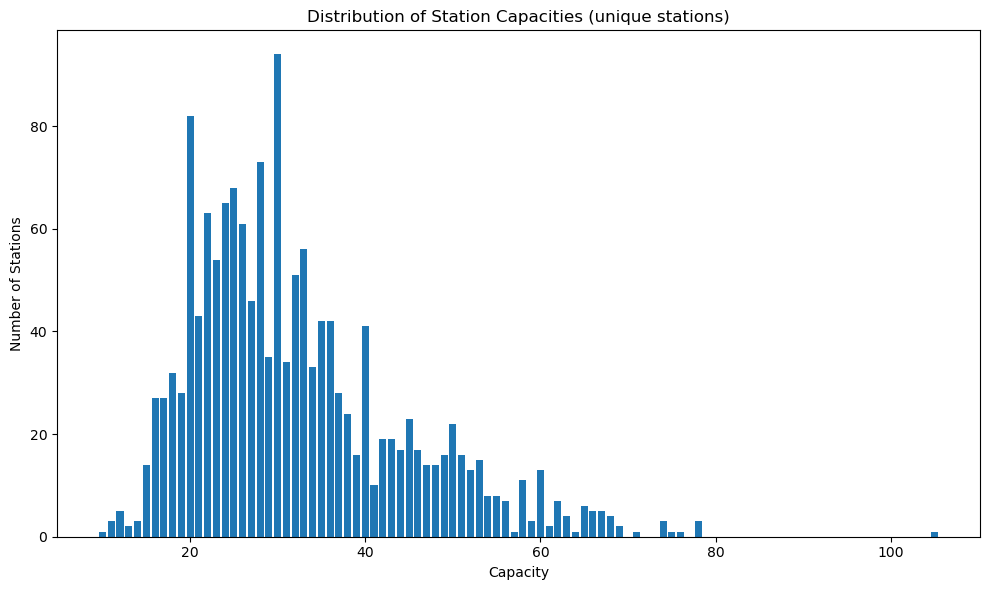

In [19]:
# Only one row per station_code to get unique capacities
station_capacity = (
    df.groupby("station_code")["capacity"]
      .max()
      .reset_index()
)

# Count how many stations have each capacity
capacity_counts = (
    station_capacity["capacity"]
    .value_counts()
    .sort_index()
    .reset_index()
)

capacity_counts.columns = ["capacity", "num_stations"]

print(f"Total stations: {station_capacity.shape[0]}")
print(f"Sum of num_stations:", capacity_counts["num_stations"].sum())
print(f"Stations with no valid capacity: ", (station_capacity.shape[0] - capacity_counts["num_stations"].sum()))


display(capacity_counts)


# Plot
plt.figure(figsize=(10,6))
plt.bar(capacity_counts["capacity"], capacity_counts["num_stations"])
plt.xlabel("Capacity")
plt.ylabel("Number of Stations")
plt.title("Distribution of Station Capacities (unique stations)")
plt.tight_layout()
plt.show()


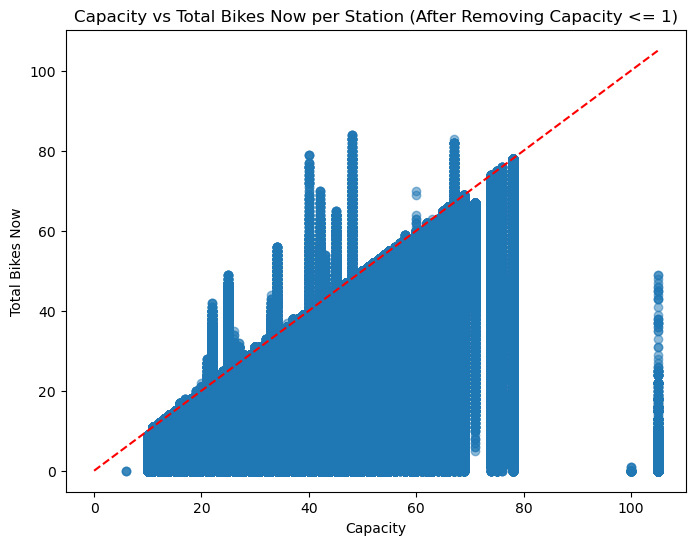

In [20]:
plt.figure(figsize=(8,6))
plt.scatter(df["capacity"], df["total_bikes_now"], alpha=0.5)
plt.plot([0, df["capacity"].max()], [0, df["capacity"].max()], color="red", linestyle="--")
plt.xlabel("Capacity")
plt.ylabel("Total Bikes Now")
plt.title("Capacity vs Total Bikes Now per Station (After Removing Capacity <= 1)")
plt.show()

# We do not see the dots at the 0 mark anymore, showing that it worked

# CHECK THE STATIONS WITH DOTS ABOVE THE RED LINE(THEY HAVE MORE BIKES THAN CAPACITY)

In [21]:
suspicious = df[df["total_bikes_now"] > df["capacity"]]
print(f"Number of suspicious stations: {suspicious.shape[0]}")
display(suspicious[["station_code", "capacity", "total_bikes_now", "total_bikes_taken"]])

Number of suspicious stations: 21572


,station_code,capacity,total_bikes_now,total_bikes_taken
683,15039,27.0,28.0,0.0
1439,42004,25.0,37.0,0.0
1488,21302,25.0,30.0,0.0
2171,15039,27.0,28.0,0.0
2933,42004,25.0,37.0,0.0
...,...,...,...,...
12601305,13123,42.0,49.0,1.0
12602045,13123,42.0,47.0,3.0
12603551,13123,42.0,50.0,0.0
12605807,13123,42.0,43.0,6.0


# CHECK THE PERCENTAGE OF IT TO NOT WRONGFULLY PURGE THE STATION WITH SMALL ERRORS

In [22]:
df["is_suspicious"] = df["total_bikes_now"] > df["capacity"]

station_stats = (
    df.groupby("station_code")
      .agg(
          total_rows=("station_code", "size"),
          suspicious_rows=("is_suspicious", "sum")
      )
)

station_stats["suspicious_ratio"] = (
    station_stats["suspicious_rows"] / station_stats["total_rows"]
)


station_stats_sorted = station_stats.sort_values("suspicious_ratio", ascending=False)
station_stats_nonzero = station_stats_sorted[station_stats_sorted["suspicious_ratio"] > 0] # Stations with at least 1 suspicious row

DROP_THRESHOLD = 0.10

stations_to_drop = station_stats_nonzero.loc[station_stats_sorted["suspicious_ratio"] >= DROP_THRESHOLD] # We will remove these stations completely
stations_to_rrow = station_stats_nonzero.loc[station_stats_sorted["suspicious_ratio"] < DROP_THRESHOLD] # We will only drop the rows

print("Stations to drop:", len(stations_to_drop))
print("Stations to remove_rows:", len(stations_to_rrow))

display(station_stats_nonzero)

Stations to drop: 9
Stations to remove_rows: 34


,total_rows,suspicious_rows,suspicious_ratio
station_code,,,
42004,8301,5234,0.630526
21302,7596,3256,0.428647
13123,8283,3137,0.378728
15056,4778,1647,0.344705
12105,4719,1003,0.212545
12127,5843,1082,0.185179
15058,7858,1199,0.152583
33019,7524,1044,0.138756
21021,8305,1132,0.136303


# SAVE VERY SUSPICIOUS TO A FILE

In [23]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/suspicious_stations.csv"
stats = df[df["station_code"].isin(station_stats_nonzero)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)
station_stats_full = station_stats_nonzero.join(stats)


with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "total_rows", "suspicious_rows", "suspicious_ratio",
        "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"
    ])
    for station, row in station_stats_full.iterrows():
        writer.writerow([
            station,
            row["total_rows"],
            row["suspicious_rows"],
            row["suspicious_ratio"],
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Suspicious stations saved: {len(station_stats_nonzero)}")
print(f"Saved: {broken_station_path}")

Suspicious stations saved: 43
Saved: ..\data\01_clean\deleted_stations/suspicious_stations.csv


In [24]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/bad_stations1.csv"
stats = df[df["station_code"].isin(station_stats_nonzero)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)
station_stats_full = station_stats_nonzero.join(stats)


with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "total_rows", "suspicious_rows", "suspicious_ratio",
        "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"
    ])
    for station, row in station_stats_full.iterrows():
        writer.writerow([
            station,
            row["total_rows"],
            row["suspicious_rows"],
            row["suspicious_ratio"],
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Broken stations saved: {len(stations_to_drop)}")
print(f"Saved: {broken_station_path}")

Broken stations saved: 9
Saved: ..\data\01_clean\deleted_stations/bad_stations1.csv


# DROP THE VERY SUSPICIOUS STATIONS

In [25]:
df = df[~df["station_code"].isin(stations_to_drop)]
log_pipeline_step(df, "Drop Stations Flagged as Corrupted")

# REMOVE THE SUSPICIOUS ROWS

In [26]:
df = df[~df['is_suspicious']]
log_pipeline_step(df, "Drop Corrupted Rows")

# REMOVE ROWS FOR STATIONS WITH MISTAKES

In [27]:
print_df(df)
mask = (df["total_bikes_now"] > df["capacity"])
df = df[~mask]
log_pipeline_step(df, "Enforce Bikes <= Capacity Constraint")
print_df(df)

Dataframe analysis
-----------------------
Shape: 
rows:     12294193
features: 24
Dataframe size: 10109426600 bytes (9641.10 MB)
-----------------------
Percentage of rows removed: 2.48%
Percentage of stations removed: 5.64%
Percentage of real rows removed: 2.48%
Percentage of real stations removed: 5.64%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
is_suspicious           bool
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07
mean,1.905255e+04,4.885773e+01,2.341761e+00,1.273573e+01,1.849473e+01,3.222129e+01,9.588082e+00,3.864456e-01,1.002962e+01,1.815204e+02,1.588756e+01
std,1.232497e+04,3.240402e-02,5.854916e-02,1.103200e+01,1.218680e+01,1.221910e+01,4.362057e+01,6.211291e-01,4.820572e+00,7.382292e+01,2.652241e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103900e+04,4.883672e+01,2.302526e+00,4.000000e+00,1.000000e+01,2.300000e+01,4.800000e+00,0.000000e+00,6.600000e+00,1.460000e+02,3.000000e+00
50%,1.701000e+04,4.885810e+01,2.343996e+00,1.000000e+01,1.700000e+01,3.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230500e+04,4.887941e+01,2.379865e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.160000e+02


Dataframe analysis
-----------------------
Shape: 
rows:     12294193
features: 24
Dataframe size: 10109426600 bytes (9641.10 MB)
-----------------------
Percentage of rows removed: 2.48%
Percentage of stations removed: 5.64%
Percentage of real rows removed: 2.48%
Percentage of real stations removed: 5.64%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
is_suspicious           bool
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07
mean,1.905255e+04,4.885773e+01,2.341761e+00,1.273573e+01,1.849473e+01,3.222129e+01,9.588082e+00,3.864456e-01,1.002962e+01,1.815204e+02,1.588756e+01
std,1.232497e+04,3.240402e-02,5.854916e-02,1.103200e+01,1.218680e+01,1.221910e+01,4.362057e+01,6.211291e-01,4.820572e+00,7.382292e+01,2.652241e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103900e+04,4.883672e+01,2.302526e+00,4.000000e+00,1.000000e+01,2.300000e+01,4.800000e+00,0.000000e+00,6.600000e+00,1.460000e+02,3.000000e+00
50%,1.701000e+04,4.885810e+01,2.343996e+00,1.000000e+01,1.700000e+01,3.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230500e+04,4.887941e+01,2.379865e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.160000e+02


In [28]:
TOTAL_REAL_ROWS_AT_START = df.shape[0]
TOTAL_REAL_STATIONS_AT_START = df["station_code"].nunique()
print(f"{TOTAL_REAL_ROWS_AT_START=}") # We will not change this anymore
print(f"{TOTAL_REAL_STATIONS_AT_START=}") # We will not change this anymore

TOTAL_REAL_ROWS_AT_START=12294193
TOTAL_REAL_STATIONS_AT_START=1505


# CHECK

In [29]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     12294193
features: 24
Dataframe size: 10109426600 bytes (9641.10 MB)
-----------------------
Percentage of rows removed: 2.48%
Percentage of stations removed: 5.64%
Percentage of real rows removed: 0.00%
Percentage of real stations removed: 0.00%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
is_suspicious           bool
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.229419e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07
mean,1.905255e+04,4.885773e+01,2.341761e+00,1.273573e+01,1.849473e+01,3.222129e+01,9.588082e+00,3.864456e-01,1.002962e+01,1.815204e+02,1.588756e+01
std,1.232497e+04,3.240402e-02,5.854916e-02,1.103200e+01,1.218680e+01,1.221910e+01,4.362057e+01,6.211291e-01,4.820572e+00,7.382292e+01,2.652241e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,6.000000e+00,-5.800000e+00,-1.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103900e+04,4.883672e+01,2.302526e+00,4.000000e+00,1.000000e+01,2.300000e+01,4.800000e+00,0.000000e+00,6.600000e+00,1.460000e+02,3.000000e+00
50%,1.701000e+04,4.885810e+01,2.343996e+00,1.000000e+01,1.700000e+01,3.000000e+01,8.100000e+00,0.000000e+00,9.500000e+00,1.800000e+02,3.000000e+00
75%,2.230500e+04,4.887941e+01,2.379865e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.040000e+01,1.000000e+00,1.300000e+01,2.220000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,4.180000e+01,3.600000e+02,3.160000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,59067,0
temperature,59067,0
weather_code,59067,0
weather_interval,59067,0
wind_direction,59067,0
wind_speed,59067,0
timestamp,55496,0
source_file,3571,0
capacity,0,0
commune_name,0,0


-----------------------


# DROP INVALID ROWS(DOESNT CONTAIN THE DATA FOR TOTAL_BIKES_NOW)

In [30]:
essential_data = [
    "station_name", 
    "station_code", 
    "postal_code", #
    "capacity", 
    "total_bikes_now", 
    "total_bikes_taken", 
    "timestamp"
]

df = df.dropna(subset=essential_data)
log_pipeline_step(df, "Drop Invalid Rows")

# RECHECK

In [31]:
print_missing(df)

Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,3571,0
source_file,3571,0
temperature,3571,0
weather_code,3571,0
weather_interval,3571,0
wind_direction,3571,0
wind_speed,3571,0
capacity,0,0
commune_name,0,0
duedate,0,0


-----------------------


# KEEPING THE USABLE COLUMNS

In [32]:
# Keep only useful columns
keep_cols = [
    "station_code",
    "latitude",
    "longitude",
    "capacity",
    "total_bikes_now",
    "total_bikes_taken",
    "timestamp",
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day"
]

df_cleaned = df[keep_cols].copy(deep=True)

print("Initial shape:", df_cleaned.shape)
print_df(df_cleaned)

Initial shape: (12238697, 12)
Dataframe analysis
-----------------------
Shape: 
rows:     12238697
features: 12
Dataframe size: 2068828658 bytes (1972.99 MB)
-----------------------
Percentage of rows removed: 2.92%
Percentage of stations removed: 5.64%
Percentage of real rows removed: 0.45%
Percentage of real stations removed: 0.00%
-----------------------


station_code           int64
latitude             float64
longitude            float64
capacity             float64
total_bikes_now      float64
total_bikes_taken    float64
timestamp             object
temperature          float64
wind_speed           float64
wind_direction       float64
weather_code         float64
is_day               float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day
count,1.223870e+07,1.223870e+07,1.223870e+07,1.223870e+07,1.223870e+07,1.223870e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07,1.223513e+07
mean,1.901415e+04,4.885792e+01,2.341644e+00,3.223853e+01,1.274993e+01,1.850485e+01,9.588082e+00,1.002962e+01,1.815204e+02,1.588756e+01,3.864456e-01
std,1.229708e+04,3.211115e-02,5.853413e-02,1.221936e+01,1.103326e+01,1.218825e+01,4.362057e+01,4.820572e+00,7.382292e+01,2.652241e+01,6.211291e-01
min,1.001000e+03,4.874339e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-5.800000e+00,0.000000e+00,4.000000e-01,0.000000e+00,-1.900000e+00
25%,1.103900e+04,4.883683e+01,2.302526e+00,2.300000e+01,4.000000e+00,1.000000e+01,4.800000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00
50%,1.700800e+04,4.885816e+01,2.343959e+00,3.000000e+01,1.000000e+01,1.700000e+01,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00
75%,2.230300e+04,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,9.000000e+02,4.180000e+01,3.600000e+02,3.160000e+02,1.510000e+01


# WEATHER TIME HANDLING

In [33]:
df_cleaned["timestamp"] = pd.to_datetime(df_cleaned["timestamp"], errors="coerce")

# Drop rows without time
df_cleaned = df_cleaned.dropna(subset=["timestamp"])

# Time features
df_cleaned["hour"] = df_cleaned["timestamp"].dt.hour
df_cleaned["day_of_week"] = df_cleaned["timestamp"].dt.dayofweek
df_cleaned["is_weekend"] = (df_cleaned["day_of_week"] >= 5).astype(int)

# Cyclical encoding(to make hour continuous and not make it jump from 23 to 0)
df_cleaned["sin_hour"] = np.sin(2 * np.pi * df_cleaned["hour"] / 24)
df_cleaned["cos_hour"] = np.cos(2 * np.pi * df_cleaned["hour"] / 24)

In [34]:
print_df(df_cleaned)

Dataframe analysis
-----------------------
Shape: 
rows:     12206106
features: 17
Dataframe size: 1660030416 bytes (1583.13 MB)
-----------------------
Percentage of rows removed: 3.18%
Percentage of stations removed: 5.83%
Percentage of real rows removed: 0.72%
Percentage of real stations removed: 0.20%
-----------------------


station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int32
day_of_week                   int32
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,12206106,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07
mean,1.901404e+04,4.885792e+01,2.341644e+00,3.223857e+01,1.275047e+01,1.850422e+01,2025-12-25 08:25:21.748314112,7.471129e+00,1.005256e+01,1.819304e+02,1.552665e+01,3.709784e-01,1.147870e+01,2.990968e+00,2.806506e-01,2.545988e-03,9.687141e-05
min,1.001000e+03,4.875740e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-5.800000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103900e+04,4.883683e+01,2.302526e+00,2.300000e+01,4.000000e+00,1.000000e+01,2025-11-29 10:00:00,4.800000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700800e+04,4.885816e+01,2.343959e+00,3.000000e+01,1.000000e+01,1.700000e+01,2025-12-25 07:30:00,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230300e+04,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.500000e+01,2026-01-20 04:15:00,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,2026-02-14 18:45:00,1.950000e+01,4.180000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.229700e+04,3.211033e-02,5.853405e-02,1.221936e+01,1.103321e+01,1.218855e+01,NaN,4.223269e+00,4.803211e+00,7.342927e+01,2.523771e+01,4.830667e-01,6.921373e+00,1.977984e+00,4.493171e-01,7.066899e-01,7.075189e-01


# CHANGE FEATURE DATA TYPES FOR MEMORY OPTIMISATION

In [35]:
"""
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "uint8",
    "total_bikes_now": "uint8",
    "total_bikes_taken": "uint8",
    "temperature": "float16",
    "wind_speed": "float16",
    "wind_direction": "float16",
    "weather_code": "uint8",
    "is_day": "uint8",
    "hour": "uint8",
    "day_of_week": "uint8",
    "is_weekend": "uint8",
    "sin_hour": "float32",
    "cos_hour": "float32"
})
"""
# We have abandoned the version above because we had problems in data due to overflow
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "int64",
    "total_bikes_now": "int64",
    "total_bikes_taken": "int64",
    "temperature": "float64",
    "wind_speed": "float64",
    "wind_direction": "float64",
    "weather_code": "int64",
    "is_day": "int64",
    "hour": "int64",
    "day_of_week": "int64",
    "is_weekend": "int64",
    "sin_hour": "float64",
    "cos_hour": "float64"
})

print_df(df_cleaned)
df_cleaned.head()

Dataframe analysis
-----------------------
Shape: 
rows:     12206106
features: 17
Dataframe size: 1708854840 bytes (1629.69 MB)
-----------------------
Percentage of rows removed: 3.18%
Percentage of stations removed: 5.83%
Percentage of real rows removed: 0.72%
Percentage of real stations removed: 0.20%
-----------------------


station_code                 uint32
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now               int64
total_bikes_taken             int64
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,12206106,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07,1.220611e+07
mean,1.901404e+04,4.885792e+01,2.341644e+00,3.223857e+01,1.275047e+01,1.850422e+01,2025-12-25 08:25:21.748314112,7.471129e+00,1.005256e+01,1.819304e+02,1.552665e+01,3.709784e-01,1.147870e+01,2.990968e+00,2.806506e-01,2.545988e-03,9.687141e-05
min,1.001000e+03,4.875740e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-5.800000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103900e+04,4.883683e+01,2.302526e+00,2.300000e+01,4.000000e+00,1.000000e+01,2025-11-29 10:00:00,4.800000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700800e+04,4.885816e+01,2.343959e+00,3.000000e+01,1.000000e+01,1.700000e+01,2025-12-25 07:30:00,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230300e+04,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.500000e+01,2026-01-20 04:15:00,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,2026-02-14 18:45:00,1.950000e+01,4.180000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.229700e+04,3.211033e-02,5.853405e-02,1.221936e+01,1.103321e+01,1.218855e+01,NaN,4.223269e+00,4.803211e+00,7.342927e+01,2.523771e+01,4.830667e-01,6.921373e+00,1.977984e+00,4.493171e-01,7.066899e-01,7.075189e-01


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
0,14111,48.837526,2.336035,25,2,22,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
1,32017,48.936269,2.358867,22,6,16,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
2,11104,48.855908,2.392571,20,2,18,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
3,5110,48.843893,2.351966,23,7,15,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
4,6108,48.847082,2.321375,17,4,11,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5


# DETECTING THE DUPLICATE ROWS(MULTIPLE ROWS FOR THE SAME (STATION, TIMESTAMP) COUPLES)

In [36]:
dup_mask = df_cleaned.duplicated(
    subset=["station_code", "timestamp"],
    keep=False
)

print(f"Duplicate rows: {dup_mask.sum()}")

display(
    df_cleaned.loc[dup_mask]
    .groupby(["station_code", "timestamp"])
    .size()
    .rename("dup_count")
    .sort_values(ascending=False)
    .head(10)
)
del dup_mask

Duplicate rows: 20565


station_code  timestamp          
17107         2025-11-07 04:00:00    4
23802         2025-11-07 03:45:00    4
14113         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
14116         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
23803         2025-11-07 04:00:00    4
              2025-11-07 03:45:00    4
14117         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
Name: dup_count, dtype: int64

# SET THE AGGREGATION RULES

In [37]:
agg_rules = {
    "latitude": "first",
    "longitude": "first",
    "capacity": "first",
    "total_bikes_now": "mean",
    "total_bikes_taken": "mean",
    "temperature": "mean",
    "wind_speed": "mean",
    "wind_direction": "mean",
    "weather_code": "first",
    "is_day": "first",
    "hour": "first",
    "day_of_week": "first",
    "is_weekend": "first",
    "sin_hour": "first",
    "cos_hour": "first",
}
# In the rows that have the same station_code and timestamp, these will be the rules to choose the value for the row that will be put there

# APPLY AGGREGATION RULES

In [38]:
before = df_cleaned.shape[0]

df_cleaned = (
    df_cleaned
    .groupby(["station_code", "timestamp"], as_index=False)
    .agg(agg_rules)
)
log_pipeline_step(df_cleaned, "Drop Duplicate Rows")

after = df_cleaned.shape[0]

print(f"Rows before: {before}")
print(f"Rows after : {after}")
print(f"Duplicates removed: {before - after}")
# We have a different number that is from what we got above. This is because we remove the extras here.

Rows before: 12206106
Rows after : 12192889
Duplicates removed: 13217


# CHECK IF THERE ARE STILL DUPLICATES

In [39]:
assert not df_cleaned.duplicated(
    ["station_code", "timestamp"]
).any()
# No error means no duplicates

# CHECK IF THERE ARE ANOMALIES IN CAPACITY SOMEHOW

In [40]:
capacity_stats = (
    df_cleaned
    .groupby('station_code')['capacity']
    .agg(['min', 'max', 'median'])
    .reset_index()
)

# Keep only stations where min != max
anomalous_stations = capacity_stats[capacity_stats['min'] != capacity_stats['max']]

print("Stations with differing min and max capacities:")
print(anomalous_stations)
# The anomalous stations keeps the stations where the capacity is not a fixed value. 
# This means there are stations where they have upgraded the slots.

Stations with differing min and max capacities:
      station_code  min  max  median
29            2004   16   17    17.0
85            4103   25   26    25.0
190           7203   24   25    25.0
259           9016   17   29    17.0
313          10029   23   24    24.0
330          10152   19   44    44.0
342          10208   10   30    30.0
390          11105   45   50    45.0
403          12006   30   41    41.0
469          12507  100  105   105.0
588          14135   38   39    39.0
623          15033   30   45    45.0
661          15108   22   36    36.0
723          16104   23   35    35.0
888          19026   17   30    30.0
910          19111   39   40    40.0
916          19121   21   35    35.0
997          20204   35   36    36.0
1168         23202   17   28    28.0


# HISTOGRAM OF ROWS

In [41]:
df_counts = df_cleaned["station_code"].value_counts().reset_index()
df_counts.columns = ["station_code", "count"]
print(df_counts)
# Row count for each station

      station_code  count
0            22001   8261
1            32603   8261
2            23903   8259
3            45003   8259
4            22012   8259
...            ...    ...
1497          2202    687
1498         35022    446
1499         18209    441
1500         34015    364
1501         40018    115

[1502 rows x 2 columns]


count
115      1
364      1
441      1
446      1
687      1
        ..
8256    56
8257    26
8258    13
8259    10
8261     2
Name: count, Length: 96, dtype: int64


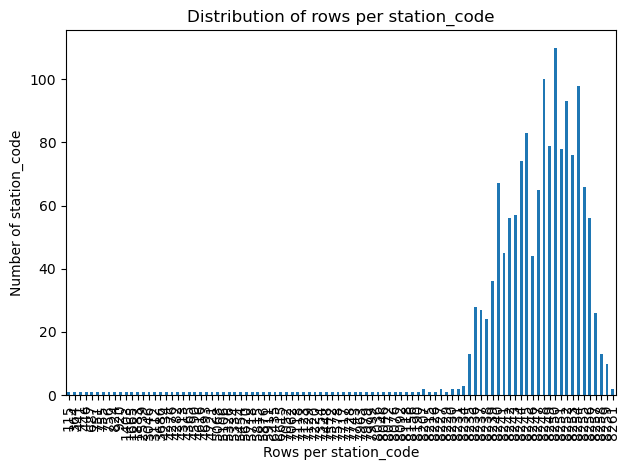

In [42]:
counts = df_cleaned["station_code"].value_counts() # index=station_code, value=#rows
count_distribution = counts.value_counts().sort_index()
print(f"{count_distribution}")
count_distribution.plot(kind="bar")
plt.xlabel("Rows per station_code")
plt.ylabel("Number of station_code")
plt.title("Distribution of rows per station_code")
plt.tight_layout()
plt.show()
# How many stations have X rows...

# MAKE THE MAP BEFORE DELETING STATIONS

In [43]:
def save_unique_stations_map_html(
    df,
    out_html="idf_stations",
    station_col="station_code",
    lat_col="latitude",
    lon_col="longitude",
    radius=0.01,               
    color="red",
    fill_opacity=0.8,
    zoom_start=10,
    tiles="CartoDB positronNoLabels",
):
    # Keep only needed cols, drop missing coords
    d = df[[station_col, lat_col, lon_col]].dropna(subset=[lat_col, lon_col])

    # To not redo the same station over and over
    d = d.drop_duplicates(subset=[station_col], keep="first")

    # Ensure numeric
    d[lat_col] = d[lat_col].astype(float)
    d[lon_col] = d[lon_col].astype(float)

    # Center map
    center_lat = float(d[lat_col].mean())
    center_lon = float(d[lon_col].mean())

    # Minimal basemap
    m = folium.Map(location=[center_lat, center_lon], zoom_start=zoom_start, tiles=tiles)

    # Plot points
    for code, la, lo in d.itertuples(index=False):
        folium.CircleMarker(
            location=[la, lo],
            radius=radius,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=fill_opacity,
            tooltip=str(code),
        ).add_to(m)
    
    out_path = f"{MAP_FOLDER}/{out_html}.html"
    m.save(out_path)

    return out_path, len(d)


In [44]:
html_path, n = save_unique_stations_map_html(df_cleaned, out_html="idf_stations_before", radius=0.01)
print("Saved:", html_path, "| stations mapped:", n)

Saved: ..\data\05_visualization\maps/idf_stations_before.html | stations mapped: 1502


# DETECT BROKEN STATIONS

In [45]:
MIN_ROWS = counts.quantile(0.05)   # up to ~5% of the stations at the bottom can be deleted

cols = ["total_bikes_now", "total_bikes_taken"]

station_stats = (
    df_cleaned
    .groupby("station_code")[cols]
    .agg(["count", "mean", "std"])
)

# To get the stations with very low row count, ~5% of the stations
# This ignores the NaN values for total_bikes_now, which will not happen anyways as we have checked it does not have NaN values
rule_few_rows = station_stats[("total_bikes_now", "count")] < MIN_ROWS

# Rules for total_bikes_now
rule_now_bad = (
    station_stats[("total_bikes_now", "std")].isna() |
    (station_stats[("total_bikes_now", "std")] < 0.1) | # Get the ones where there are no big change
    (station_stats[("total_bikes_now", "mean")] < 0.5) # Get the ones where it is almost always 0
)

# Rules for total_bikes_taken
rule_taken_bad = (
    station_stats[("total_bikes_taken", "std")].isna() |
    (station_stats[("total_bikes_taken", "std")] < 0.1) | # Get the ones where there are no big change
    (station_stats[("total_bikes_taken", "mean")] < 0.5) # Get the ones where it is almost always 0
)

bad_stations = station_stats[
    rule_few_rows | rule_now_bad | rule_taken_bad # Union them
].index

print(f"{rule_few_rows.sum()} stations removed by row count")
print(f"{rule_now_bad.sum()} stations removed by bikes_now stats")
print(f"{rule_taken_bad.sum()} stations removed by bikes_taken stats")
print(f"Stations to remove: {len(bad_stations)}")

good_stations = df_cleaned["station_code"].unique()
good_stations = [s for s in good_stations if s not in bad_stations]

print(f"Stations to keep: {len(good_stations)}")
# Here we can see how many stations are affected by specific rules.
# We will need to remove them to keep the data integrity.


76 stations removed by row count
10 stations removed by bikes_now stats
7 stations removed by bikes_taken stats
Stations to remove: 79
Stations to keep: 1423


# REMOVE THE BROKEN STATIONS

In [46]:
print_df(df_cleaned)

df_kept = df_cleaned[df_cleaned["station_code"].isin(good_stations)].copy()
log_pipeline_step(df_kept, "Drop Broken Stations")

print_df(df_kept)

Dataframe analysis
-----------------------
Shape: 
rows:     12192889
features: 17
Dataframe size: 1609461480 bytes (1534.90 MB)
-----------------------
Percentage of rows removed: 3.29%
Percentage of stations removed: 5.83%
Percentage of real rows removed: 0.82%
Percentage of real stations removed: 0.20%
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,1.219289e+07,12192889,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07,1.219289e+07
mean,1.901383e+04,2025-12-25 09:34:25.242741504,4.885792e+01,2.341643e+00,3.223861e+01,1.274995e+01,1.850466e+01,7.468120e+00,1.005623e+01,1.819551e+02,1.554016e+01,3.713335e-01,1.148590e+01,2.990289e+00,2.809319e-01,1.798418e-03,-4.379183e-04
min,1.001000e+03,2025-11-04 04:00:00,4.875740e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-5.800000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103900e+04,2025-11-29 12:00:00,4.883683e+01,2.302526e+00,2.300000e+01,4.000000e+00,1.000000e+01,4.800000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700800e+04,2025-12-25 09:00:00,4.885816e+01,2.343959e+00,3.000000e+01,1.000000e+01,1.700000e+01,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230300e+04,2026-01-20 04:45:00,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2026-02-14 18:45:00,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,1.950000e+01,4.180000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.229709e+04,NaN,3.211023e-02,5.853359e-02,1.221950e+01,1.103350e+01,1.218817e+01,4.224225e+00,4.803954e+00,7.345744e+01,2.524701e+01,4.831614e-01,6.920485e+00,1.978679e+00,4.494543e-01,7.065738e-01,7.076370e-01


Dataframe analysis
-----------------------
Shape: 
rows:     11736642
features: 17
Dataframe size: 1643129880 bytes (1567.01 MB)
-----------------------
Percentage of rows removed: 6.91%
Percentage of stations removed: 10.78%
Percentage of real rows removed: 4.54%
Percentage of real stations removed: 5.45%
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,1.173664e+07,11736642,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07,1.173664e+07
mean,1.904067e+04,2025-12-25 07:54:04.528725504,4.885773e+01,2.341675e+00,3.232137e+01,1.278110e+01,1.855714e+01,7.470782e+00,1.005259e+01,1.819949e+02,1.552788e+01,3.715913e-01,1.148608e+01,2.989532e+00,2.807843e-01,1.771170e-03,-8.646133e-04
min,1.001000e+03,2025-11-04 04:00:00,4.876462e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-5.800000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.104300e+04,2025-11-29 09:45:00,4.883682e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,4.800000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700700e+04,2025-12-25 06:45:00,4.885799e+01,2.343670e+00,3.000000e+01,1.000000e+01,1.700000e+01,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2.220800e+04,2026-01-20 03:00:00,4.887936e+01,2.379407e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2026-02-14 18:45:00,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,4.180000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.231882e+04,NaN,3.189356e-02,5.826625e-02,1.209640e+01,1.105017e+01,1.203490e+01,4.223842e+00,4.800397e+00,7.343383e+01,2.523814e+01,4.832300e-01,6.918852e+00,1.978658e+00,4.493824e-01,7.065172e-01,7.076932e-01


# BUILD THE FULL BUT EMPTY(FOR NOW) DATAFRAME

In [47]:
# Min/max timestamp per station
station_ranges = (
    df_kept
    .groupby("station_code")["timestamp"]
    .agg(["min", "max"])
)

dfs = []

for station, (start, end) in station_ranges.iterrows():
    full_index = pd.date_range(start, end, freq="15min")

    full_df = pd.DataFrame({
        "station_code": station,
        "timestamp": full_index
    })

    merged = full_df.merge(
        df_kept[df_kept["station_code"] == station],
        on=["station_code", "timestamp"],
        how="left"
    )

    dfs.append(merged)

df_full = pd.concat(dfs, ignore_index=True).copy()
log_pipeline_step(df_full, "Build Full Dataframe")

print(f"Rows after full timeline: {len(df_full)}")
print(f"Added rows: {len(df_full) - len(df_kept)}")
# We build the dataset by adding the missing timestamps in the dataset
# We can see that there were a lot of timestamps missing.

Rows after full timeline: 14019326
Added rows: 2282684


# SPLIT THE DATASET

In [48]:
df_full["split"] = -1

df_full = df_full.sort_values(by=["station_code", "timestamp"]).reset_index(drop=True) # Crucial

for station_code, df_station in df_full.groupby("station_code"):
    n = len(df_station)
    train_end = int(0.7 * n)
    val_end = int(0.85 * n)

    # Get original indices
    idx = df_station.index
    df_full.loc[idx[:train_end], "split"] = 0 # "train"
    df_full.loc[idx[train_end:val_end], "split"] = 1 # "val"
    df_full.loc[idx[val_end:], "split"] = 2 # "test"

# Here we split the dataset. 
# By marking them like that, it is impossible to accidently use the test values.
# Also the sorting by station_code and timestamp part is important,
# this gives a chronological split between the rows for each station and not just randomize it.
# Randomizing it might make biases towards specific stations.

# SEPERATE THE DATASET

In [49]:
train_dataset = df_full[df_full["split"] == 0].copy(deep=True)
val_dataset   = df_full[df_full["split"] == 1].copy(deep=True)
test_dataset  = df_full[df_full["split"] == 2].copy(deep=True)

datasets = [train_dataset, val_dataset, test_dataset]

print(f"Train rows: {len(train_dataset)}")
print(f"Val rows:   {len(val_dataset)}")
print(f"Test rows:  {len(test_dataset)}")
datasets = [train_dataset, val_dataset, test_dataset]

Train rows: 9812973
Val rows:   2103159
Test rows:  2103194


# DETECT MISSING ROWS

In [50]:
for dataset, name in zip(datasets, ["train", "val", "test"]):
    missing_rows = dataset[dataset["total_bikes_now"].isna()]

    missing_per_station = (
        missing_rows
        .groupby(["station_code", "split"])
        .size()
        .sort_values(ascending=False)
    )

    print(f"Stations with most missing rows({name}):")
    display(missing_per_station.head(10))

# We can see that most of the missing rows are in the train set, and somehow test dataset has more missing rows than validation.

Stations with most missing rows(train):


station_code  split
1015          0        1129
23803         0        1127
1012          0        1127
23802         0        1127
42028         0        1126
42026         0        1126
42015         0        1126
2012          0        1126
1023          0        1126
42024         0        1126
dtype: int64

Stations with most missing rows(val):


station_code  split
6006          1        256
21109         1        256
14018         1        251
15006         1        251
42209         1        251
14132         1        251
15129         1        251
6030          1        251
14136         1        251
14001         1        251
dtype: int64

Stations with most missing rows(test):


station_code  split
32012         2        251
21007         2        251
21027         2        251
21023         2        251
21033         2        251
21016         2        251
22602         2        251
19123         2        251
19202         2        250
22601         2        250
dtype: int64

# FILL STATIC COLUMNS

In [51]:
static_cols = ["latitude", "longitude"] # Will be the same for its own station

for dsi in range(len(datasets)):
    datasets[dsi][static_cols] = (datasets[dsi]
                            .groupby("station_code")[static_cols]
                            .transform(
                                lambda x: x.ffill().bfill()
                            ))

    # Capacity needs its own treatment as it changes over time
    datasets[dsi]["capacity"] = (
        datasets[dsi]
        .groupby("station_code")["capacity"]
        .transform(lambda x: x.ffill()) # Forward-fill bc backward-fill might cause data leak
    )

# We fill the static data first.

# DETECT MISSING ROWS

In [52]:
for dataset, name in zip(datasets, ["train", "val", "test"]):
    missing_rows = dataset[dataset["total_bikes_now"].isna()]

    missing_per_station = (
        missing_rows
        .groupby(["station_code", "split"])
        .size()
        .sort_values(ascending=False)
    )

    print(f"Stations with most missing rows({name}):")
    display(missing_per_station.head(10))

# We can see that most of the missing rows are in the train set, and somehow test dataset has more missing rows than validation.

Stations with most missing rows(train):


station_code  split
1015          0        1129
23803         0        1127
1012          0        1127
23802         0        1127
42028         0        1126
42026         0        1126
42015         0        1126
2012          0        1126
1023          0        1126
42024         0        1126
dtype: int64

Stations with most missing rows(val):


station_code  split
6006          1        256
21109         1        256
14018         1        251
15006         1        251
42209         1        251
14132         1        251
15129         1        251
6030          1        251
14136         1        251
14001         1        251
dtype: int64

Stations with most missing rows(test):


station_code  split
32012         2        251
21007         2        251
21027         2        251
21023         2        251
21033         2        251
21016         2        251
22602         2        251
19123         2        251
19202         2        250
22601         2        250
dtype: int64

# FILL WEATHER DATA WITH FORWARD FILL

In [53]:
weather_cols = [
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day"
]

for dsi in range(len(datasets)):
    for col in weather_cols:
        datasets[dsi][col] = (
            datasets[dsi]
            .groupby("station_code")[col]
            .transform(lambda g: g.ffill().bfill())
        )

# We fill the weather data by forward-filling only to avoid data leakage

# FILL BIKE DATA WITH INTERPOLATION

In [54]:
bike_cols = ["total_bikes_now", "total_bikes_taken"]

# Interpolate per station using timestamp as index
def interpolate_bikes(group):
    group = group.set_index("timestamp")  # DatetimeIndex required
    # This makes a linear fill.
    # For example if we have 3, _, 5 then it will fill _ with 4.
    group[bike_cols] = group[bike_cols].interpolate(method="time")
    return group.reset_index() # To keep the dataframe same as before

In [55]:
for dsi in range(len(datasets)):
    datasets[dsi] = datasets[dsi].groupby("station_code").apply(interpolate_bikes).reset_index(drop=True)
    # Fill edges
    datasets[dsi][bike_cols] = datasets[dsi][bike_cols].fillna(method="ffill")
# We first fill the data with a linear way first using interpolate(method="time"), then we fill the edge with forward fill.

C:\Users\emirh\AppData\Local\Temp\ipykernel_54500\2958497423.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  datasets[dsi] = datasets[dsi].groupby("station_code").apply(interpolate_bikes).reset_index(drop=True)
C:\Users\emirh\AppData\Local\Temp\ipykernel_54500\2958497423.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  datasets[dsi][bike_cols] = datasets[dsi][bike_cols].fillna(method="ffill")
C:\Users\emirh\AppData\Local\Temp\ipykernel_54500\2958497423.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping 

# FILL THE REST OF THE TIME DATA

In [56]:
for dsi in range(len(datasets)):
    datasets[dsi]["hour"] = datasets[dsi]["timestamp"].dt.hour.astype("int64")
    datasets[dsi]["day_of_week"] = datasets[dsi]["timestamp"].dt.dayofweek.astype("int64")
    datasets[dsi]["is_weekend"] = (datasets[dsi]["day_of_week"] >= 5).astype("int64")
    datasets[dsi]["sin_hour"] = np.sin(2 * np.pi * datasets[dsi]["hour"] / 24).astype("float64")
    datasets[dsi]["cos_hour"] = np.cos(2 * np.pi * datasets[dsi]["hour"] / 24).astype("float64")
# To fill them, we use the same way we have made them at the first place.
# We add the astype to keep the data type same.

# CHECK

In [57]:
print("Remaining NaNs per column:")
temp = pd.concat(datasets, ignore_index=True)
print(temp.isna().sum())

print("Final rows:", len(temp))
print("Final stations:", temp["station_code"].nunique())

Remaining NaNs per column:
timestamp               0
station_code            0
latitude                0
longitude               0
capacity             1012
total_bikes_now         1
total_bikes_taken       1
temperature             0
wind_speed              0
wind_direction          0
weather_code            0
is_day                  0
hour                    0
day_of_week             0
is_weekend              0
sin_hour                0
cos_hour                0
split                   0
dtype: int64
Final rows: 14019326
Final stations: 1423


# MAKE THE MAP AFTER DELETING/REFILLING

In [58]:
html_path, n = save_unique_stations_map_html(temp, radius=0.01, out_html="idf_stations_removed_refilled")
print("Saved:", html_path, "| stations mapped:", n)
# This way we can see if the broken stations are at around the same place in the map.

Saved: ..\data\05_visualization\maps/idf_stations_removed_refilled.html | stations mapped: 1423


# SAVE THE BROKEN STATIONS IN A FILE

In [59]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/broken_stations2.csv"
stats = df_cleaned[df_cleaned["station_code"].isin(bad_stations)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)

with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"])
    for station, row in stats.iterrows():
        writer.writerow([
            station,
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Broken stations saved: {len(bad_stations)}")
print(f"Saved: {broken_station_path}")
# If we see NaN values, it means it always had that value for every row.

Broken stations saved: 79
Saved: ..\data\01_clean\deleted_stations/broken_stations2.csv


# CHECK

In [60]:
print(temp.isna().sum().sort_values(ascending=False))
# Check if we have any NaN values

capacity             1012
total_bikes_now         1
total_bikes_taken       1
timestamp               0
is_day                  0
cos_hour                0
sin_hour                0
is_weekend              0
day_of_week             0
hour                    0
wind_direction          0
weather_code            0
station_code            0
wind_speed              0
temperature             0
longitude               0
latitude                0
split                   0
dtype: int64


# DETAILS

In [61]:
print_df(temp)

Dataframe analysis
-----------------------
Shape: 
rows:     14019326
features: 18
Dataframe size: 2018783076 bytes (1925.26 MB)
-----------------------
Percentage of rows removed: -11.20%
Percentage of stations removed: 10.78%
Percentage of real rows removed: -14.03%
Percentage of real stations removed: 5.45%
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
split                         int64
dtype: object

-----------------------


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,split
count,14019326,1.401933e+07,1.401933e+07,1.401933e+07,1.401831e+07,1.401932e+07,1.401932e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07
mean,2025-12-25 11:22:52.131949312,1.904058e+04,4.885773e+01,2.341683e+00,3.232135e+01,1.278034e+01,1.855826e+01,7.462367e+00,1.006686e+01,1.816401e+02,1.562137e+01,3.711135e-01,1.149699e+01,2.999198e+00,2.805536e-01,7.394681e-04,-2.778367e-03,4.500607e-01
min,2025-11-04 04:00:00,1.001000e+03,4.876462e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-5.800000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00
25%,2025-11-29 19:45:00,1.104300e+04,4.883682e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,4.800000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01,0.000000e+00
50%,2025-12-25 11:30:00,1.700700e+04,4.885799e+01,2.343670e+00,3.000000e+01,1.000000e+01,1.700000e+01,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16,0.000000e+00
75%,2026-01-20 03:15:00,2.220800e+04,4.887936e+01,2.379407e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01,1.000000e+00
max,2026-02-14 18:45:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,4.180000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
std,NaN,1.231843e+04,3.189307e-02,5.826518e-02,1.209609e+01,1.104010e+01,1.202341e+01,4.227680e+00,4.805382e+00,7.360245e+01,2.530136e+01,4.831028e-01,6.909414e+00,1.975489e+00,4.492697e-01,7.074451e-01,7.067625e-01,7.399650e-01


# ADD BIKE LAG

In [62]:
for dsi in range(len(datasets)):
    datasets[dsi] = datasets[dsi].sort_values(["station_code", "timestamp"]) # Just in case
    datasets[dsi]["total_bikes_lag1"] = datasets[dsi].groupby("station_code")["total_bikes_now"].shift(1)
    datasets[dsi]["total_bikes_lag2"] = datasets[dsi].groupby("station_code")["total_bikes_now"].shift(2)
    datasets[dsi] = datasets[dsi].dropna(subset=["total_bikes_lag1", "total_bikes_lag2"]).copy()
# We just put the value from 1 or 2 rows before(after sorting and grouping of course).
# This will make the values for the first and second row NaN, but this is not a significant number for the dataset.
# Thats why we can just drop it.

# LAST CHECK

In [63]:
print_df(temp)
print_missing(temp)
del temp

Dataframe analysis
-----------------------
Shape: 
rows:     14019326
features: 18
Dataframe size: 2018783076 bytes (1925.26 MB)
-----------------------
Percentage of rows removed: -11.20%
Percentage of stations removed: 10.78%
Percentage of real rows removed: -14.03%
Percentage of real stations removed: 5.45%
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
split                         int64
dtype: object

-----------------------


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,split
count,14019326,1.401933e+07,1.401933e+07,1.401933e+07,1.401831e+07,1.401932e+07,1.401932e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07,1.401933e+07
mean,2025-12-25 11:22:52.131949312,1.904058e+04,4.885773e+01,2.341683e+00,3.232135e+01,1.278034e+01,1.855826e+01,7.462367e+00,1.006686e+01,1.816401e+02,1.562137e+01,3.711135e-01,1.149699e+01,2.999198e+00,2.805536e-01,7.394681e-04,-2.778367e-03,4.500607e-01
min,2025-11-04 04:00:00,1.001000e+03,4.876462e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-5.800000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00
25%,2025-11-29 19:45:00,1.104300e+04,4.883682e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,4.800000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01,0.000000e+00
50%,2025-12-25 11:30:00,1.700700e+04,4.885799e+01,2.343670e+00,3.000000e+01,1.000000e+01,1.700000e+01,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16,0.000000e+00
75%,2026-01-20 03:15:00,2.220800e+04,4.887936e+01,2.379407e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01,1.000000e+00
max,2026-02-14 18:45:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,4.180000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
std,NaN,1.231843e+04,3.189307e-02,5.826518e-02,1.209609e+01,1.104010e+01,1.202341e+01,4.227680e+00,4.805382e+00,7.360245e+01,2.530136e+01,4.831028e-01,6.909414e+00,1.975489e+00,4.492697e-01,7.074451e-01,7.067625e-01,7.399650e-01


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
capacity,1012,0
total_bikes_now,1,0
total_bikes_taken,1,0
cos_hour,0,0
day_of_week,0,0
hour,0,0
is_day,0,0
is_weekend,0,0
latitude,0,0
longitude,0,0


-----------------------


# SAVE ONLY THE STATIONS AND THEIR COORDINATES

In [64]:
station_info_cols = [
    "station_code",
    "station_name",
    "latitude",
    "longitude",
    "commune_name",
    "postal_code",
    "capacity"
]

# Columns to take from df (all station info columns except capacity)
static_cols = [c for c in station_info_cols if c not in ["station_code", "capacity"]]

# Take metadata from df
df_meta = df[["station_code"] + static_cols].drop_duplicates(subset=["station_code"], keep="first")

# Take latest capacity per station from df_full
df_capacity = df_full.groupby("station_code")["capacity"].last().reset_index()

# Merge metadata with latest capacity, only for stations in df_full
df_station_info = df_meta.merge(df_capacity, on="station_code", how="inner")

# Reorder columns according to station_info_cols
existing_cols = [c for c in station_info_cols if c in df_station_info.columns]
df_station_info = df_station_info[existing_cols]

# Sort it for easier use in menu later
df_station_info = df_station_info.sort_values(["commune_name", "station_name"]).reset_index(drop=True)

# Save CSV
df_station_info.to_csv(f"{COORDINATES_FOLDER}/station_info.csv", index=False)
print(f"Station info saved to: {COORDINATES_FOLDER}/station_info.csv")

# We need the station_info_cols to make a menu in our program(to use the models later in real time).
# Capacity is for a fallback case, in case we cannot get velib data in our program.

Station info saved to: ..\data\02_features\station_coordinates/station_info.csv


# REMERGE FROM THE DATASET SPLIT

In [65]:
df_final = pd.concat(datasets, ignore_index=True)
log_pipeline_step(df_final, "Final Dataset Concatenation")

# CHECK AND DROP NAN ROWS

In [66]:
print_df(df_final)
print_missing(df_final)

Dataframe analysis
-----------------------
Shape: 
rows:     14010787
features: 20
Dataframe size: 2241726052 bytes (2137.88 MB)
-----------------------
Percentage of rows removed: -11.13%
Percentage of stations removed: 10.78%
Percentage of real rows removed: -13.96%
Percentage of real stations removed: 5.45%
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
split                         int64
total_bikes_lag1            float64
total_bikes_lag2            float64
dtype: object

-----------------------


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,split,total_bikes_lag1,total_bikes_lag2
count,14010787,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07,1.401079e+07
mean,2025-12-25 11:21:21.511182080,1.904058e+04,4.885773e+01,2.341683e+00,3.232144e+01,1.278027e+01,1.855845e+01,7.461271e+00,1.006690e+01,1.816279e+02,1.562906e+01,3.711365e-01,1.150136e+01,2.999401e+00,2.807246e-01,4.203697e-04,-2.941192e-03,4.497255e-01,1.278049e+01,1.278067e+01
min,2025-11-04 04:30:00,1.001000e+03,4.876462e+01,2.165597e+00,1.000000e+01,0.000000e+00,0.000000e+00,-5.800000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2025-11-29 19:45:00,1.104300e+04,4.883682e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,4.700000e+00,6.600000e+00,1.460000e+02,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01,0.000000e+00,4.000000e+00,4.000000e+00
50%,2025-12-25 11:15:00,1.700700e+04,4.885799e+01,2.343670e+00,3.000000e+01,1.000000e+01,1.700000e+01,8.100000e+00,9.500000e+00,1.800000e+02,3.000000e+00,0.000000e+00,1.200000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16,0.000000e+00,1.000000e+01,1.000000e+01
75%,2026-01-20 03:00:00,2.220800e+04,4.887936e+01,2.379407e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.040000e+01,1.300000e+01,2.220000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01,1.000000e+00,1.800000e+01,1.800000e+01
max,2026-02-14 18:45:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,4.180000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,7.800000e+01,7.800000e+01
std,NaN,1.231843e+04,3.189308e-02,5.826519e-02,1.209615e+01,1.104006e+01,1.202323e+01,4.228592e+00,4.806491e+00,7.362265e+01,2.530715e+01,4.831089e-01,6.908657e+00,1.975834e+00,4.493532e-01,7.074815e-01,7.067257e-01,7.397913e-01,1.104001e+01,1.103991e+01


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
capacity,0,0
cos_hour,0,0
day_of_week,0,0
hour,0,0
is_day,0,0
is_weekend,0,0
latitude,0,0
longitude,0,0
sin_hour,0,0
split,0,0


-----------------------


# LAST HEAD

In [67]:
display(df_final.head(10))
log_pipeline_step(df_final, "Final Dataframe")

,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,split,total_bikes_lag1,total_bikes_lag2
0,2025-11-04 04:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.0,8.0,207.0,3.0,0.0,4,1,0,0.866025,5.000000e-01,0,2.0,2.0
1,2025-11-04 04:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.2,203.0,3.0,0.0,4,1,0,0.866025,5.000000e-01,0,2.0,2.0
2,2025-11-04 05:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.2,203.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,0,2.0,2.0
3,2025-11-04 05:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.1,201.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,0,2.0,2.0
4,2025-11-04 05:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.4,200.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,0,2.0,2.0
5,2025-11-04 05:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.1,8.7,197.0,3.0,0.0,5,1,0,0.965926,2.588190e-01,0,2.0,2.0
6,2025-11-04 06:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.2,8.7,197.0,2.0,0.0,6,1,0,1.000000,6.123234e-17,0,2.0,2.0
7,2025-11-04 06:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.2,8.7,197.0,2.0,1.0,6,1,0,1.000000,6.123234e-17,0,2.0,2.0
8,2025-11-04 06:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.2,8.7,197.0,2.0,1.0,6,1,0,1.000000,6.123234e-17,0,2.0,2.0
9,2025-11-04 06:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.3,8.6,202.0,2.0,1.0,6,1,0,1.000000,6.123234e-17,0,2.0,2.0


# SAVE THE PIPELINE LOGS

In [68]:
pipeline_stats_df = pd.DataFrame(pipeline_stats)

pipeline_stats_df.to_csv(
    PIPELINE_STATS_FOLDER / "pipeline_stats.csv",
    index=False
)

print(f"Saved: {PIPELINE_STATS_FOLDER}/pipeline_stats.csv")

Saved: ..\data\06_statistics\pipeline/pipeline_stats.csv


# SAVE THE FINAL CLEAN DATASET

In [69]:
df_final.to_csv(f"{DATASET_OUTPUT_FOLDER}/{FINAL_CSV_FILE_NAME}.csv", index=False)
print(f"Clean dataset saved: {FINAL_CSV_FILE_NAME}.csv")

Clean dataset saved: final_clean_split_data.csv
